# Attention Residuals: let each layer choose which earlier layers to read

*Kimi Team (Moonshot AI), "Attention Residuals", technical report, March 2026 ([arXiv 2603.15031](https://arxiv.org/abs/2603.15031)). The scalable variant, Block AttnRes, is used by Inkling 2 Small in the diagram this series follows. Notebook 9 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** In every transformer the layers are connected by a **residual stream**: each layer adds its output to a running sum, $h_l=h_{l-1}+f_{l-1}(h_{l-1})$, so what layer $l$ reads is the *unweighted sum* of the embedding and everything every earlier layer wrote. Nobody has ever chosen those weights; they are all 1. The paper's observation: sequences had the same problem before attention. An RNN squeezes the past into one state; attention replaced that by letting each position **look back at all earlier positions with learned, data-dependent weights**. Depth is the same: replace the fixed sum by a **softmax over the earlier layers' outputs**, with a learned query per layer. That is **Attention Residuals (AttnRes)**. Because depth is small (tens to hundreds of layers) this attention is cheap. The scalable version groups layers into $N$ blocks, sums inside a block, and attends over the block sums (about 8 of them), cutting memory and communication from $O(Ld)$ to $O(Nd)$.

We rebuild both variants, test the pieces the paper's argument depends on (the softmax over depth, the merging of partial softmaxes that makes the blocked version exact, the growth of hidden-state size with depth), and train small models with ordinary, full and blocked residuals.

| step | what we do |
|---|---|
| 1 | the residual stream, and what it hides |
| 2 | attention over depth: the equation, in code |
| 3 | Full AttnRes in a small transformer; the paper's unified "depth mixing" picture |
| 4 | Block AttnRes: blocks, partial sums, and exact merging with an online softmax |
| 5 | experiment: loss for standard, full and blocked residuals |
| 6 | experiment: what the learned depth weights look like; what happens to hidden-state size |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. The residual stream hides a choice

A transformer layer $f_l$ (an attention or a feed-forward sublayer) does not replace its input; it adds to it. Unrolled, the input to layer $l$ is

$$ h_l = h_1 + \sum_{i<l} f_i(h_i) . $$

That is the whole mechanism behind how well deep networks train: gradients can run straight through the sum. But look at it as a **mixing rule**: layer $l$ receives the embedding and each earlier layer's output with weight exactly 1. The paper lists three consequences:

1. **No selective access.** An attention sublayer and an MLP sublayer receive the same sum, though they may want different parts of it.
2. **Irreversible loss.** Once an output is added into the sum, a later layer cannot take it back out or turn it down.
3. **Output growth.** Because every layer adds on top of the same stream, the stream's magnitude grows with depth (the paper says $O(L)$), and a later layer has to produce larger and larger outputs to stay influential once the stream is normalised before it. The paper calls this **PreNorm dilution**: each layer's relative contribution is progressively diluted.

An earlier fix, **highway networks**, makes the weights learned and per-feature: $h_l=(1-g_l)\odot h_{l-1}+g_l\odot f_{l-1}(h_{l-1})$ with a gate $g_l$. But the paper's point is that highway-style gates still only see the single compressed state $h_{l-1}$, not the individual earlier outputs.

We check consequence 3 on a small trained model later (section 6). First the replacement.

## 2. Attention over depth

Do for depth what attention did for time. Layer $l$'s input becomes a **weighted sum over the earlier sources** (the embedding $v_0=h_1$ and the outputs $v_i=f_i(h_i)$ for $1\le i<l$), with weights from a softmax:

$$ h_l=\sum_{i=0}^{l-1}\alpha_{i\to l}\,v_i,\qquad \alpha_{i\to l}=\frac{\exp\!\big(w_l^\top\mathrm{RMSNorm}(v_i)\big)}{\sum_{j=0}^{l-1}\exp\!\big(w_l^\top\mathrm{RMSNorm}(v_j)\big)} \qquad(\text{paper eq. 1 to 4}) . $$

Three choices, each with a reason:

- **The query $w_l$ is a learned vector, one per layer, not computed from the token.** It is a parameter, independent of the forward computation; that independence is what makes a blocked, efficient version possible (section 4).
- **Keys and values are the layer outputs themselves** (keys are normalised).
- **RMSNorm on the keys.** Without it a layer that produced big outputs would dominate the softmax just by magnitude.

The cost is tiny: one vector and one norm per sublayer. For one token the arithmetic is $O(L^2d)$ over all layers and $O(Ld)$ memory for the stored outputs, small next to sequence-length attention. Here is the module (the kit's `DepthAttn`); `sources` is the list of tensors $[v_0,\dots,v_{l-1}]$, each $[B,T,d]$:

In [2]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w


def rope_angles(pos, dh, base=10000.0):
    """pos: integer tensor of any shape -> angles [..., dh/2]."""
    inv = base ** (-torch.arange(0, dh, 2, dtype=torch.float32) / dh)
    return pos.to(torch.float32)[..., None] * inv


def apply_rope(x, pos):
    """x: [..., dh] (pairs are (even, odd) channels); pos broadcasts against x[..., 0]."""
    ang = rope_angles(pos, x.shape[-1])
    c, s = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * c - x2 * s
    out[..., 1::2] = x1 * s + x2 * c
    return out


def attend(q, k, v, mask, sink=None):
    """Explicit softmax attention.
    q [B,H,T,d]  k,v [B,H,S,d]  mask bool, broadcastable to [B,H,T,S] (True = may look)
    sink: optional [H] learned logit. It is one extra softmax column that has no value vector:
          the probability it takes is simply thrown away (gpt-oss style).
    returns out [B,H,T,d], probs [B,H,T,S] (without the sink column)."""
    B, H, T, d = q.shape
    s = (q @ k.transpose(-1, -2)) / math.sqrt(d)
    s = s.masked_fill(~mask, float("-inf"))
    if sink is not None:
        s = torch.cat([s, sink.view(1, H, 1, 1).expand(B, H, T, 1)], dim=-1)
    p = s.softmax(-1)
    if sink is not None:
        p = p[..., :-1]
    return p @ v, p

class DepthAttn(nn.Module):
    """One attention-over-depth step (paper's block_attn_res).  A learned pseudo-query w (one vector per
    sublayer) scores the RMS-normalised earlier representations; softmax over the depth axis; weighted sum."""
    def __init__(self, d):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(d))       # zero init => uniform average over sources at the start
        self.norm = RMSNorm(d)

    def forward(self, sources):
        V = torch.stack(sources)                      # [N, B, T, d]
        logits = torch.einsum("d,nbtd->nbt", self.w, self.norm(V))
        a = logits.softmax(0)
        self.last = a.detach()
        return torch.einsum("nbt,nbtd->btd", a, V)

In [3]:
torch.manual_seed(0)
d_ = 32
da = A.DepthAttn(d_)
srcs = [torch.randn(2, 5, d_) for _ in range(5)]
h = da(srcs)
print("weights at initialisation (query = 0), for one token:", np.round(da.last[:, 0, 0].numpy(), 3))
check("with a zero query the weights are uniform: the layer starts as an average over its sources", torch.allclose(da.last, torch.full_like(da.last, 0.2)))
check("the output is the plain average of the sources at initialisation", torch.allclose(h, sum(srcs) / 5, atol=1e-6))
with torch.no_grad():
    da.w.copy_(torch.randn(d_) * 3)
da(srcs)
check("after the query changes, the weights are still a distribution over depth (sum to 1 for every token)", torch.allclose(da.last.sum(0), torch.ones(2, 5), atol=1e-6))
check("and they are no longer uniform", (da.last - 0.2).abs().max() > 0.05)
mag = [torch.randn(2, 5, d_) * s for s in (1, 1, 1, 1000)]
da.w.data.zero_(); da(mag)
check("RMSNorm on the keys: a source 1000x larger gets no more attention at a zero query (the average is not hijacked)", torch.allclose(da.last, torch.full_like(da.last, 0.25), atol=1e-6))

weights at initialisation (query = 0), for one token: [0.2 0.2 0.2 0.2 0.2]
PASS - with a zero query the weights are uniform: the layer starts as an average over its sources 
PASS - the output is the plain average of the sources at initialisation 
PASS - after the query changes, the weights are still a distribution over depth (sum to 1 for every token) 
PASS - and they are no longer uniform 
PASS - RMSNorm on the keys: a source 1000x larger gets no more attention at a zero query (the average is not hijacked) 


Note the initialisation: with a zero query, **every layer starts as the average of its sources**, not the sum. That is not the standard residual (which sums). The paper does the same: it initialises all queries to zero so that training starts from an equal-weight average, which it reports prevents training volatility. It is also scale-safe, because the next sublayer normalises its input anyway.

## 3. Full AttnRes in a transformer, and the unified picture

A sublayer here means an attention layer or a feed-forward layer (the paper counts each as a layer). So a transformer with $n$ blocks has $L=2n$ sublayers. In Full AttnRes **each sublayer has its own query $w_l$ and its own RMSNorm**, and reads a softmax mixture of the embedding and all earlier sublayer outputs, one fresh mixture per sublayer. The kit's `MiniLM(res="full")` is that: `outs` starts as `[embedding]`, every sublayer's output is appended, and `self.mix[m]` mixes `outs` to produce sublayer $m$'s input. The paper's Figure 1 shows the three residual schemes side by side:

![The paper's Figure 1. (a) Standard residuals: uniform additive accumulation. (b) Full AttnRes: each layer selectively aggregates all previous layer outputs via learned attention weights (the green w is the layer's query, the red alpha the attention operation). (c) Block AttnRes: layers are grouped into blocks, reducing memory from O(Ld) to O(Nd).](../../assets/architecture_gallery/attnres_fig1_overview.png)

A useful way to compare them, which the paper develops in its Section 6.2: every scheme is a **depth-mixing matrix** $M$, where $M_{l,i}$ is the weight with which sublayer $l$'s input includes source $i$. Standard residuals: all ones below the diagonal. Highway: a product structure of gates. Full AttnRes: a dense lower-triangular matrix of softmax weights that **varies with the token**. Block AttnRes: the same but with the rows of a block sharing sources. Their Figure 9 draws $M$ for a 4-layer example:

![The paper's Figure 9: depth mixing matrices M for four residual variants (standard residual, highway, Full AttnRes, Block AttnRes with block size 2), L = 4.](../../assets/architecture_gallery/attnres_fig9_matrices.png)

We will draw our own $M$ from a trained model in section 6.

## 4. Block AttnRes: blocks, partial sums, exact merging

Full AttnRes has a systems problem. At scale, activations are recomputed and layers are split across devices (pipeline parallelism): every layer's output would have to be kept, and sent between devices, for *all* later layers. Memory and communication then scale as $O(Ld)$.

**Block AttnRes** groups the $L$ sublayers into $N$ blocks of $S=L/N$. Inside a block the outputs are **summed** into one representation $b_n=\sum_{j\in\mathcal B_n}f_j(h_j)$ (paper eq. 5). Across blocks, the softmax attention runs over only $N$ block representations plus the embedding ($b_0=h_1$). A sublayer in the middle of a block additionally sees the **partial sum** of the block so far, $b_n^{i-1}$. Memory and communication drop to $O(Nd)$; the paper finds $N\approx8$ recovers most of the benefit at all scales (so only 8 stored hidden states per token). The paper's Figure 2 is the pseudo-code, which our `MiniLM(res="block")` follows line for line:

```python
def block_attn_res(blocks, partial_block, proj, norm):
    V = torch.stack(blocks + [partial_block])                  # [N+1, B, T, D]
    K = norm(V)
    logits = torch.einsum('d, n b t d -> n b t', proj.weight.squeeze(), K)
    h = torch.einsum('n b t, n b t d -> b t d', logits.softmax(0), V)
    return h
```

(The paper's code does exactly what our `DepthAttn` does: `norm`, a dot product with the learned query, softmax over the source axis, weighted sum.)

**Two checks of the design.** First, the two extremes: if each block has one sublayer ($N=L$), Block AttnRes is Full AttnRes. We build both with the same weights and compare outputs:

In [4]:
data = A.CharData()
Dm, Hh = 64, 4
def mk(res, nb, n_layers=2, seed=0):
    torch.manual_seed(seed)
    return A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: A.SwiGLU(Dm, 128), n_layers=n_layers, res=res, n_blocks=nb)

full, blk = mk("full", None), mk("block", 4)                       # 2 layers = 4 sublayers; 4 blocks of 1 sublayer
blk.load_state_dict(full.state_dict())
for m_ in list(full.mix) + list(blk.mix):                           # give the queries non-trivial values so the test is not just "uniform = uniform"
    pass
torch.manual_seed(5)
with torch.no_grad():
    for a, b in zip(full.mix, blk.mix):
        w = torch.randn_like(a.w); a.w.copy_(w); b.w.copy_(w)
idx = torch.randint(0, data.vocab, (2, 16))
err = (full(idx) - blk(idx)).abs().max().item()
print("N = L: max |Full - Block| =", err)
check("Block AttnRes with one sublayer per block is exactly Full AttnRes", err < 1e-5)
n_src = lambda L_, N_: (L_, N_ + 1)
print(f"sources stored per token at L = 96 sublayers: Full {n_src(96, 8)[0]}, Block with N = 8: {n_src(96, 8)[1]}")

N = L: max |Full - Block| = 0.0
PASS - Block AttnRes with one sublayer per block is exactly Full AttnRes 
sources stored per token at L = 96 sublayers: Full 96, Block with N = 8: 9


**Second, the exact merge.** The blocked version has an efficiency trick. Because the queries $w_l$ are *parameters* (not functions of the running computation), the attention logits of **every sublayer in a block over the earlier, completed blocks** can all be computed up front, in parallel, before the block's own sublayers run. Only the part that involves the growing partial sum needs to be computed sequentially. To combine the two parts without changing the answer, the paper uses an **online softmax**: each part returns its maximum logit $m$, its sum of exponentials $\ell$ and its unnormalised weighted sum $o$, and the parts are merged by rescaling to a common maximum. The check below splits a set of sources into a "completed blocks" group and a "partial sum" group, merges, and compares with the joint softmax:

In [5]:
def partial_softmax(logits, V):
    """logits [n], V [n, d] -> (max, sum of exp, unnormalised weighted sum)"""
    m = logits.max()
    e = torch.exp(logits - m)
    return m, e.sum(), (e[:, None] * V).sum(0)

def merge(a, b):
    ma, la, oa = a; mb, lb, ob = b
    m = torch.maximum(ma, mb)
    sa, sb = torch.exp(ma - m), torch.exp(mb - m)
    return (oa * sa + ob * sb) / (la * sa + lb * sb)

torch.manual_seed(0)
n_blocks_done, d_ = 5, 8
V = torch.randn(n_blocks_done + 1, d_) * 2
logits = torch.randn(n_blocks_done + 1) * 3
joint = torch.softmax(logits, 0) @ V
inter = partial_softmax(logits[:n_blocks_done], V[:n_blocks_done])       # computed in parallel for the whole block
intra = partial_softmax(logits[n_blocks_done:], V[n_blocks_done:])       # depends on the partial sum: computed per sublayer
merged = merge(inter, intra)
print("max |merged - joint softmax| =", (merged - joint).abs().max().item())
check("online-softmax merging of the two parts is exactly the joint softmax", torch.allclose(merged, joint, atol=1e-6))

max |merged - joint softmax| = 2.384185791015625e-07
PASS - online-softmax merging of the two parts is exactly the joint softmax 


So the blocked schedule changes nothing about the math: it is a way of arranging the same softmax so that most of it can be batched, and that is what lets the paper report a measured end-to-end training overhead of less than 4% under pipeline parallelism (negligible without it) and an inference latency overhead of less than 2% on typical workloads. We cannot measure either here.

## 5. Experiment: loss for standard, full and blocked residuals

A small language model with 6 layers (12 sublayers: 6 attention, 6 feed-forward), width 64, 4 heads, character-level text, 300 steps, 3 seeds, all else identical. Variants: **standard** residuals; **Full AttnRes**; **Block AttnRes** with $N=6$ (2 sublayers per block), $N=3$ (4 per block) and $N=2$ (6 per block).

In [6]:
NLY = 6
def build(variant, seed):
    torch.manual_seed(seed)
    res, nb = {"standard": ("std", None), "full": ("full", None), "block N=6": ("block", 6), "block N=3": ("block", 3), "block N=2": ("block", 2)}[variant]
    return A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: A.SwiGLU(Dm, 128), n_layers=NLY, res=res, n_blocks=nb)

variants = ["standard", "full", "block N=6", "block N=3", "block N=2"]
for v in variants:
    print(f"{v:10s} parameters {sum(p.numel() for p in build(v, 0).parameters()):,}")
vals, models, times = {}, {}, {}
t0 = time.time()
for v in variants:
    out = []
    t1 = time.time()
    for s in [0, 1, 2]:
        mdl = build(v, s)
        A.train_lm(mdl, data, steps=300, B=32, T=64, lr=3e-3, seed=s)
        out.append(A.evaluate(mdl, data))
        if s == 0: models[v] = mdl
    vals[v] = np.array(out); times[v] = (time.time() - t1) / 3
    print(f"{v:10s} val loss {vals[v].mean():.3f} +- {vals[v].std():.3f}  seeds {np.round(out, 3)}   ({time.time() - t0:.0f} s)")

standard   parameters 258,880
full       parameters 260,544
block N=6  parameters 260,544
block N=3  parameters 260,544
block N=2  parameters 260,544


standard   val loss 2.561 +- 0.016  seeds [2.581 2.559 2.542]   (50 s)


full       val loss 2.502 +- 0.028  seeds [2.538 2.497 2.47 ]   (202 s)


block N=6  val loss 2.527 +- 0.026  seeds [2.555 2.492 2.534]   (292 s)


block N=3  val loss 2.548 +- 0.027  seeds [2.585 2.521 2.539]   (356 s)


block N=2  val loss 2.546 +- 0.035  seeds [2.592 2.508 2.538]   (418 s)


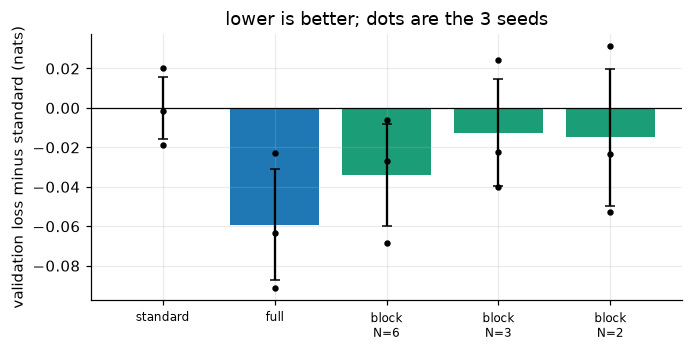

largest seed spread 0.035
time per training run (s), CPU, includes evaluation: {'standard': 16.5, 'full': 50.9, 'block N=6': 30.1, 'block N=3': 21.3, 'block N=2': 20.5}
PASS - Full AttnRes has a lower mean loss than the standard residual, by more than one largest seed spread 0.059 vs spread 0.035
PASS - the gain shrinks as the number of blocks falls: full < block N=6 < block N=2 (means) 
PASS - every AttnRes variant has a lower mean loss than the standard residual 


In [7]:
base = vals["standard"].mean(); spread = max(x.std() for x in vals.values())
fig, ax = plt.subplots(figsize=(6.4, 3.3))
for i, v in enumerate(variants):
    ax.bar(i, vals[v].mean() - base, yerr=vals[v].std(), color=[C["grey"], C["blue"], C["green"], C["green"], C["green"]][i], capsize=3)
    ax.scatter([i] * 3, vals[v] - base, color="k", s=10, zorder=3)
ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(5)); ax.set_xticklabels([v.replace(" ", "\n") for v in variants], fontsize=8)
ax.set_ylabel("validation loss minus standard (nats)"); ax.set_title("lower is better; dots are the 3 seeds"); plt.tight_layout(); plt.show()
print(f"largest seed spread {spread:.3f}")
print("time per training run (s), CPU, includes evaluation:", {v: round(t, 1) for v, t in times.items()})
check("Full AttnRes has a lower mean loss than the standard residual, by more than one largest seed spread", base - vals["full"].mean() > spread, f"{base - vals['full'].mean():.3f} vs spread {spread:.3f}")
check("the gain shrinks as the number of blocks falls: full < block N=6 < block N=2 (means)", vals["full"].mean() < vals["block N=6"].mean() < vals["block N=2"].mean())
check("every AttnRes variant has a lower mean loss than the standard residual", all(vals[v].mean() < base for v in variants[1:]))

**Result (3 seeds; validation loss in nats; parameters: 258,880 for the standard model, 260,544 for every AttnRes variant, 0.6% more).** Standard 2.561, Full AttnRes **2.502**, Block $N=6$ 2.527, Block $N=3$ 2.548, Block $N=2$ 2.546, against a largest seed-to-seed spread of 0.035. Full AttnRes is 0.059 better than the standard residual, about 1.7 spreads, and each of its three seeds is at least as good as the best standard seed. The ordering follows the number of depth sources: full (12 sources) beats $N=6$, which beats $N=3$ and $N=2$, which are only 0.013 to 0.015 better than standard, inside the noise. That is the direction of the paper's finding (more sources help; a handful of blocks recover part of it), and the size of the Full gain is suggestive, but with three seeds and a spread this large we call it **suggestive and not established**. The paper's scaling-law result (Block AttnRes with about 8 blocks matching a baseline trained on 1.25x more compute) is at a scale we cannot reach. **Cost**, on this CPU with a Python loop, per training run: standard 16.5 s, Full 50.9 s (3.1x), Block $N=6$ 30 s (1.8x), $N=3$ 21 s, $N=2$ 20.5 s (these timings moved by tens of percent between our runs, because the machine was shared). That overhead is an artefact of an unfused implementation on a CPU (the paper reports less than 4% on real training), but it does show that more sources cost more arithmetic.

## 6. What do the learned depth weights look like, and what happens to hidden-state size?

Two measurements from the trained models. **(a)** The learned mixing matrix $M$ of the Full AttnRes model: for each sublayer, the average weight it puts on each earlier source (averaged over tokens and a validation batch), drawn the way the paper's Figure 9 draws its matrices. The paper's Figure 8 shows the same kind of thing for a large trained model (their depth-wise attention distributions): the interesting patterns there are a strong weight on the **embedding**, and a preference for **nearby** layers.

![The paper's Figure 8: depth-wise attention weight distributions for a 16-head model with full (top) and block (bottom) AttnRes.](../../assets/architecture_gallery/attnres_fig8_weights.png)

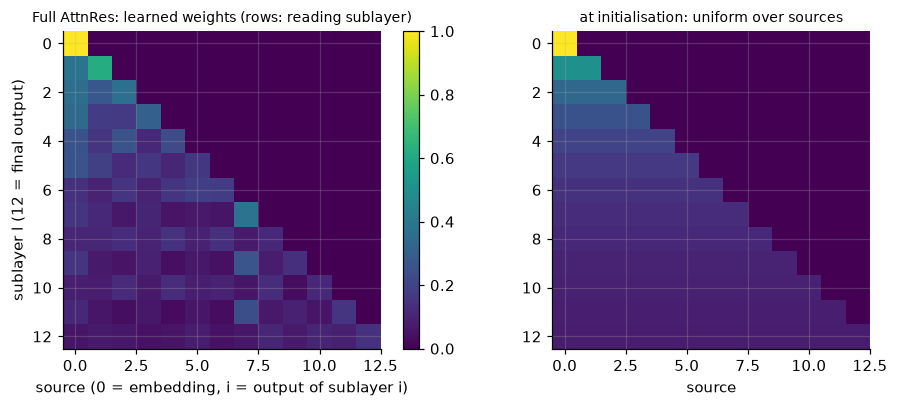

weight on the embedding by sublayer 1..12:    [0.38 0.36 0.35 0.25 0.26 0.14 0.15 0.11 0.15 0.09 0.11 0.06]
uniform would be                               [0.5  0.33 0.25 0.2  0.17 0.14 0.12 0.11 0.1  0.09 0.08 0.08]
weight on the previous sublayer's output:      [0.27 0.17 0.11 0.11 0.18 0.06 0.07 0.08 0.03 0.06 0.09]  (for l = 2..12)
largest deviation from uniform: 0.257
PASS - the learned weights moved away from uniform 


In [8]:
@torch.no_grad()
def depth_matrix(model, n_batches=4):
    g = torch.Generator().manual_seed(21)
    L = model.n_sub
    M = np.zeros((L + 1, L + 1))                                           # row: sublayer index (L = final output), column: source index
    model.eval()
    for _ in range(n_batches):
        seq = data.batch("val", 16, 64, g)
        model(seq[:, :-1])
        for l, mix in enumerate(model.mix):
            w = mix.last.mean((1, 2)).numpy()                              # [n_sources]
            M[l, :len(w)] += w / n_batches
    model.train()
    return M

Mfull = depth_matrix(models["full"])
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.8))
im = axs[0].imshow(Mfull, cmap="viridis"); axs[0].set_title("Full AttnRes: learned weights (rows: reading sublayer)", fontsize=9)
axs[0].set_xlabel("source (0 = embedding, i = output of sublayer i)"); axs[0].set_ylabel("sublayer l (12 = final output)"); plt.colorbar(im, ax=axs[0], fraction=.046)
uni = np.zeros_like(Mfull)
for l in range(Mfull.shape[0]): uni[l, :l + 1] = 1 / (l + 1)
axs[1].imshow(uni, cmap="viridis"); axs[1].set_title("at initialisation: uniform over sources", fontsize=9); axs[1].set_xlabel("source")
plt.tight_layout(); plt.show()
dev = np.abs(Mfull - uni).max()
emb = Mfull[1:, 0]; uni_emb = uni[1:, 0]
print("weight on the embedding by sublayer 1..12:   ", np.round(Mfull[1:, 0], 2))
print("uniform would be                              ", np.round(uni_emb, 2))
print("weight on the previous sublayer's output:     ", np.round([Mfull[l, l - 1] for l in range(2, 13)], 2), " (for l = 2..12)")
print(f"largest deviation from uniform: {dev:.3f}")
check("the learned weights moved away from uniform", dev > 0.05)

**Result.** The learned weights moved well away from the uniform start (largest deviation 0.26). Two readable patterns. The **embedding** keeps a large share for the first several sublayers (0.38, 0.36, 0.35, 0.25, 0.26, 0.14 for the second to the seventh), *above* what a uniform average would give for the third to the sixth (0.36, 0.35, 0.25, 0.26 against 0.33, 0.25, 0.20, 0.17), and falls to 0.06 by the last, so early layers keep reading the raw tokens. And the **previous sublayer's output** gets between 0.03 and 0.27, by no means the dominant source: the layers read widely across depth instead of mostly the last one. The paper's Figure 8 shows the same kind of picture for its large model (strong embedding weight, spread across other layers), which we mention as a resemblance; this is one toy model with one seed, and we did not test whether the pattern is stable.

**(b) Hidden-state size.** The paper's third complaint about standard residuals is that the stream grows with depth. We measure the average norm of each sublayer's **input** and **output** (per token) for the standard model and the Full AttnRes model, on validation text, over the 12 sublayers.

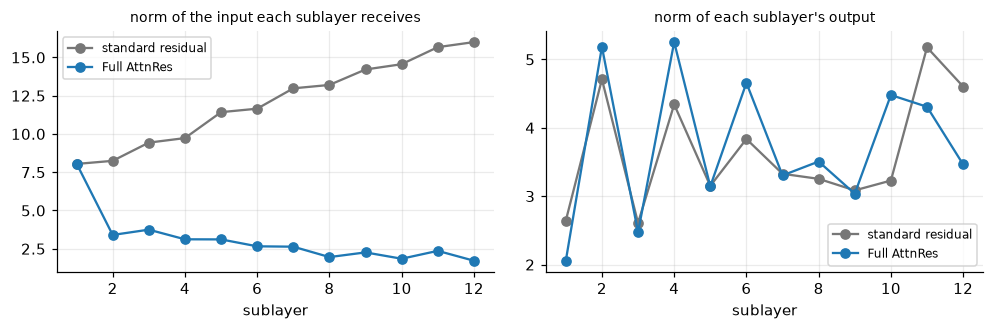

standard : input norm first/last sublayer 8.04 16.0  (x2.0)   output norm first/last 2.64 4.6  (x1.7)
Full     : input norm first/last sublayer 8.07 1.72  (x0.2)   output norm first/last 2.06 3.46  (x1.7)
PASS - in the standard model the stream's norm grows with depth 


In [9]:
@torch.no_grad()
def norms(model):
    model.trace_on = True
    seq = data.batch("val", 16, 64, torch.Generator().manual_seed(8))
    model.eval(); model(seq[:, :-1]); model.train()
    tr = {k: np.array(v) for k, v in model.tr.items()}
    model.trace_on = False
    return tr

nstd, nfull = norms(models["standard"]), norms(models["full"])
fig, axs = plt.subplots(1, 2, figsize=(9, 3.1), sharex=True)
for ax, key, title in [(axs[0], "in", "norm of the input each sublayer receives"), (axs[1], "out", "norm of each sublayer's output")]:
    ax.plot(range(1, 13), nstd[key], marker="o", label="standard residual", color=C["grey"])
    ax.plot(range(1, 13), nfull[key], marker="o", label="Full AttnRes", color=C["blue"])
    ax.set_title(title, fontsize=9); ax.set_xlabel("sublayer"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("standard : input norm first/last sublayer", round(nstd["in"][0], 2), round(nstd["in"][-1], 2), f" (x{nstd['in'][-1] / nstd['in'][0]:.1f})   output norm first/last", round(nstd["out"][0], 2), round(nstd["out"][-1], 2), f" (x{nstd['out'][-1] / nstd['out'][0]:.1f})")
print("Full     : input norm first/last sublayer", round(nfull["in"][0], 2), round(nfull["in"][-1], 2), f" (x{nfull['in'][-1] / nfull['in'][0]:.1f})   output norm first/last", round(nfull["out"][0], 2), round(nfull["out"][-1], 2), f" (x{nfull['out'][-1] / nfull['out'][0]:.1f})")
check("in the standard model the stream's norm grows with depth", nstd["in"][-1] > nstd["in"][0])

**Result (one model of each kind, validation text).** In the standard model the norm of the stream entering the last sublayer is **twice** that entering the first (8.0 to 16.0): the growth with depth that the paper describes (their "uncontrolled hidden-state growth"), reproduced. In the Full AttnRes model the input does **not** grow (8.1 to 1.7), which is expected by construction: the input is a weighted average of earlier outputs, so it cannot be bigger than the biggest of them, and later layers read a mixture where the standard model reads a sum. But the **output** of the sublayers still grows with depth in both (about 1.7x from the first to the last, 2.6 to 4.6 for standard and 2.1 to 3.5 for Full AttnRes), so the paper's finding that AttnRes keeps output magnitudes uniform across depth is **not reproduced** in our toy. We did not look into why; with 12 sublayers there is little depth to dilute.

## What this notebook did and did not show

**Shown (checks).** The depth softmax is a proper distribution over earlier sources and starts uniform; RMSNorm on the keys stops large-output layers from dominating; Block AttnRes with one sublayer per block is exactly Full AttnRes; the online-softmax merge that lets the blocked version batch its inter-block attention is exact; the standard residual stream grows with depth in our trained model. Sections 5 and 6 report the loss comparison, the learned weight matrix and the norm measurements, and what each says.

**Not shown.** The paper's results are for Kimi Linear (48B total, 3B active) trained on 1.4T tokens, scaling-law fits over five model sizes in which Block AttnRes matches the loss of a baseline trained with 1.25x more compute (their Figure 4), downstream benchmarks (GPQA-Diamond, HumanEval), and system overheads under pipeline parallelism, with a cache-based communication scheme (their Figure 3) that we did not implement. Ours is a 12-sublayer toy trained for 300 steps on characters. Likewise we did not test the paper's block-size sweep at scale (their Figure 6), their architecture sweep (Figure 7), or compare against other residual variants such as highway networks and hyper-connections (in the DeepSeek-V4 series, the mHC notebook covers a neighbouring idea).

**End of the series.** The nine notebooks together: GQA (1), the attention output gate (2), attention sinks and windows (3), DeepSeek Sparse Attention (4), Gated DeltaNet (5), Kimi Delta Attention (6), LatentMoE (7), quantile balancing (8), Attention Residuals (9).

In [10]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 12 | failed: 0
